<a href="https://colab.research.google.com/github/20canpolat09-gif/Data-Visualization-with-Python-Hands-On-Projects/blob/main/FashionMNISTProject_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Project: Fashion-MNIST Classification

Build a convolutional neural network (CNN) in PyTorch to classify the 10 Fashion-MNIST clothing categories. Run every code cell from top to bottom in an internet-enabled Jupyter/Colab environment and save the notebook with outputs before submitting.

## 1. Import libraries
We use PyTorch, torchvision, NumPy, and Matplotlib.

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


## 2. Load and prepare Fashion-MNIST
Images are resized to 16×16, converted to tensors, and normalized. The official training set is split into training and validation subsets.

In [5]:
BATCH_SIZE = 64
transform = transforms.Compose([
    transforms.Resize((16, 16)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_size = 54000
val_size = len(train_full) - train_size
train_dataset, val_dataset = random_split(
    train_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Image tensor shape:", tuple(train_full[0][0].shape))

Training images: 54000
Validation images: 6000
Test images: 10000
Image tensor shape: (1, 16, 16)


## 3. Display the first validation image resized to 16×16
The first validation image is shown with its class label.

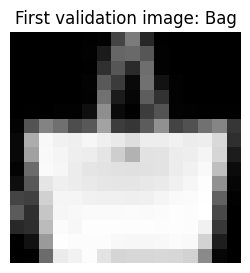

Image tensor shape: (1, 16, 16)
Label: Bag


In [6]:
first_val_image, first_val_label = val_dataset[0]
plt.figure(figsize=(3, 3))
plt.imshow(first_val_image.squeeze().numpy() * 0.5 + 0.5, cmap="gray")
plt.title(f"First validation image: {class_names[first_val_label]}")
plt.axis("off")
plt.show()
print("Image tensor shape:", tuple(first_val_image.shape))
print("Label:", class_names[first_val_label])

## 4. Display the first three validation images
All three validation samples are resized to 16×16 and displayed with their labels.

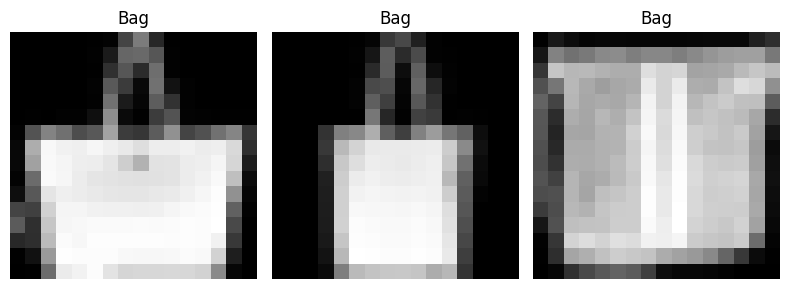

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for index, ax in enumerate(axes):
    image, label = val_dataset[index]
    ax.imshow(image.squeeze().numpy() * 0.5 + 0.5, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Define the convolutional neural network
Two convolutional and max-pooling blocks extract image features. With 16×16 inputs, the feature maps are 4×4 before the classifier.

In [8]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 6. Configure loss and optimizer
Cross-entropy is used for multi-class classification. The required optimizer is stochastic gradient descent (SGD) with learning rate 0.1.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)
EPOCHS = 5
print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


## 7. Train the CNN
Each epoch performs forward propagation, computes cross-entropy loss, backpropagates gradients, and updates model weights. Validation accuracy is measured without updating weights.

In [11]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            total_loss += loss.item() * inputs.size(0)
            correct += (outputs.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
for epoch in range(EPOCHS):
    model.train()
    running_loss, seen = 0.0, 0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        seen += targets.size(0)

    train_loss = running_loss / seen
    val_loss, val_accuracy = evaluate(model, val_loader, criterion)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss: {train_loss:.4f} | "
          f"Validation loss: {val_loss:.4f} | Validation accuracy: {val_accuracy:.2%}")

Epoch 1/5 | Train loss: 0.5846 | Validation loss: 0.4738 | Validation accuracy: 82.07%
Epoch 2/5 | Train loss: 0.4395 | Validation loss: 0.3989 | Validation accuracy: 85.17%
Epoch 3/5 | Train loss: 0.3819 | Validation loss: 0.3668 | Validation accuracy: 86.50%
Epoch 4/5 | Train loss: 0.3477 | Validation loss: 0.3299 | Validation accuracy: 87.77%
Epoch 5/5 | Train loss: 0.3242 | Validation loss: 0.3208 | Validation accuracy: 88.83%


## 8. Plot training cost and validation accuracy
The first plot shows training cost (loss) over epochs; the second shows validation accuracy.

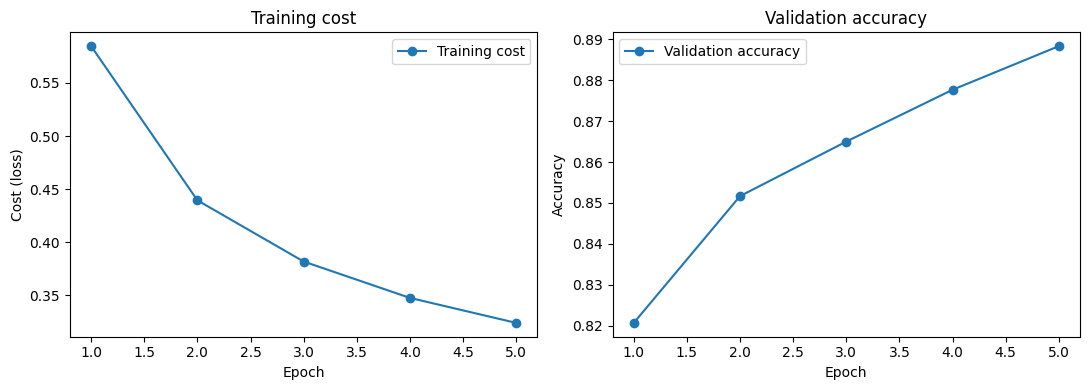

In [12]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Training cost")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cost (loss)")
axes[0].set_title("Training cost")
axes[0].legend()
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Validation accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on the test set
The held-out test set estimates performance on unseen images.

In [13]:
test_loss, test_accuracy = evaluate(model, test_loader, criterion)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.3382
Test accuracy: 87.92%


## 10. Inspect sample predictions
Compare predicted labels with the true labels for a batch of test images.

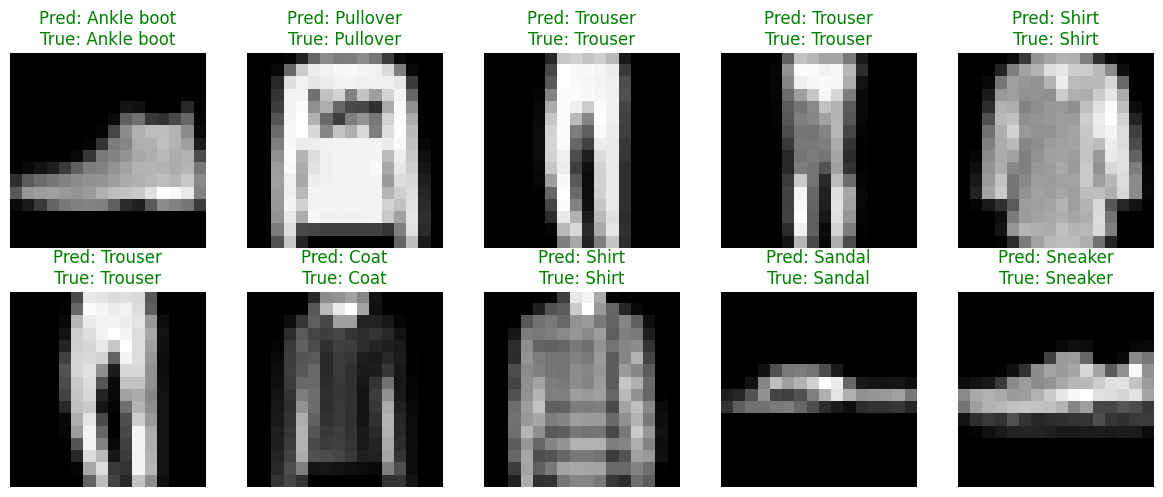

In [14]:
model.eval()
test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    predictions = model(test_images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image = test_images[i].squeeze().numpy() * 0.5 + 0.5
    true_name = class_names[test_labels[i].item()]
    pred_name = class_names[predictions[i].item()]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Pred: {pred_name}\nTrue: {true_name}",
                 color=("green" if predictions[i] == test_labels[i] else "red"))
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Conclusion and reflection

This project prepared Fashion-MNIST images, displayed resized validation samples, implemented and trained a CNN, plotted training cost and validation accuracy, and evaluated the model on held-out test data.

1. **Why use a CNN?** Convolutional filters learn local visual patterns such as edges and textures while preserving spatial structure.
2. **What does max pooling do?** It reduces feature-map dimensions and computation while retaining salient activations.
3. **Why use validation data?** It helps monitor generalization during training without using the test set for tuning.
4. **How can performance be improved?** Experiment with more epochs, learning rates, batch sizes, data augmentation, and alternative architectures while monitoring validation performance.